In [15]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum, avg, count, round, month, dayofweek, hour 

spark = (
    SparkSession.builder
    .appName("NYC Subway - Part 1 - weather")
    .getOrCreate()
)

SILVER = "../data/silver"
GOLD = "../data/gold"
RESULTS = "../results"


## reading and approving data 

In [16]:
station_hour = spark.read.parquet(SILVER + "/station_hour")
complexes = spark.read.parquet(SILVER + "/complexes")
weather_hour = spark.read.parquet(SILVER + "/weather_hour")

print("Station-hour rows:", station_hour.count())
print("Station complexes:", complexes.count())
print("Weather-hour rows:", weather_hour.count())


Station-hour rows: 3620146
Station complexes: 445
Weather-hour rows: 8704


## Aggregate ridership across the network

In [17]:
network_hour = station_hour.groupBy("transit_timestamp").agg(
    sum("riders").alias("riders")
)

print("Hours with ridership:", network_hour.count())

network_hour.orderBy("transit_timestamp").show(10, truncate=False)

Hours with ridership: 8759
+-------------------+------+
|transit_timestamp  |riders|
+-------------------+------+
|2024-07-01 00:00:00|23252 |
|2024-07-01 01:00:00|10539 |
|2024-07-01 02:00:00|6591  |
|2024-07-01 03:00:00|7279  |
|2024-07-01 04:00:00|18894 |
|2024-07-01 05:00:00|64288 |
|2024-07-01 06:00:00|129125|
|2024-07-01 07:00:00|219992|
|2024-07-01 08:00:00|293953|
|2024-07-01 09:00:00|199116|
+-------------------+------+
only showing top 10 rows



## Join ridership with weather

In [18]:
# Keep only hours with a known weather condition
weather_labeled = weather_hour.where("condition is not null")

# Join hourly network ridership to the weather for the same hour
hours = network_hour.join(
    weather_labeled,
    network_hour.transit_timestamp == weather_labeled.hour_local,
    "inner" # keeps only rows that have a matching timestamp in both DataFrames
)

print("Hours with ridership:", network_hour.count())
print("Hours with a weather label:", weather_labeled.count())
print("Hours with both:", hours.count())

hours.groupBy("condition").count().orderBy("condition").show()


Hours with ridership: 8759
Hours with a weather label: 8387
Hours with both: 8387
+----------+-----+
| condition|count|
+----------+-----+
|       dry| 7753|
|heavy rain|  110|
|light rain|  459|
|      snow|   65|
+----------+-----+



## extract mounth , days , hours

In [19]:
from pyspark.sql.functions import month, dayofweek, hour

hours = hours.withColumn(
    "month", month("transit_timestamp")
).withColumn(
    "day", dayofweek("transit_timestamp")
).withColumn(
    "hour", hour("transit_timestamp")
)

hours.select(
    "transit_timestamp", "month", "day", "hour", "riders", "condition"
).show(5, truncate=False)

+-------------------+-----+---+----+------+---------+
|transit_timestamp  |month|day|hour|riders|condition|
+-------------------+-----+---+----+------+---------+
|2024-08-23 09:00:00|8    |6  |9   |170303|dry      |
|2024-08-03 09:00:00|8    |7  |9   |100641|dry      |
|2024-07-04 15:00:00|7    |5  |15  |149731|dry      |
|2024-11-04 04:00:00|11   |2  |4   |19288 |dry      |
|2025-04-14 16:00:00|4    |2  |16  |302140|dry      |
+-------------------+-----+---+----+------+---------+
only showing top 5 rows



In [20]:
hours = hours.withColumn(
    "month", month("transit_timestamp")
).withColumn(
    "day", dayofweek("transit_timestamp")
).withColumn(
    "hour", hour("transit_timestamp")
)

hours.select(
    "transit_timestamp", "month", "day", "hour", "riders", "condition"
).show(5, truncate=False)


+-------------------+-----+---+----+------+---------+
|transit_timestamp  |month|day|hour|riders|condition|
+-------------------+-----+---+----+------+---------+
|2024-08-23 09:00:00|8    |6  |9   |170303|dry      |
|2024-08-03 09:00:00|8    |7  |9   |100641|dry      |
|2024-07-04 15:00:00|7    |5  |15  |149731|dry      |
|2024-11-04 04:00:00|11   |2  |4   |19288 |dry      |
|2025-04-14 16:00:00|4    |2  |16  |302140|dry      |
+-------------------+-----+---+----+------+---------+
only showing top 5 rows



## create our baseline for comparison

In [22]:
normal = (
    hours
    .where("condition = 'dry'")
    .groupBy("month", "day", "hour")
    .agg(avg("riders").alias("usual_riders"))
)

print("Baseline groups:", normal.count())
normal.orderBy("month", "day", "hour").show(10, truncate=False)

Baseline groups: 2013
+-----+---+----+------------+
|month|day|hour|usual_riders|
+-----+---+----+------------+
|1    |1  |0   |36302.25    |
|1    |1  |1   |18080.25    |
|1    |1  |2   |10262.75    |
|1    |1  |3   |7501.5      |
|1    |1  |4   |9608.25     |
|1    |1  |5   |16795.0     |
|1    |1  |6   |31604.25    |
|1    |1  |7   |46509.25    |
|1    |1  |8   |62535.25    |
|1    |1  |9   |81839.75    |
+-----+---+----+------------+
only showing top 10 rows



## compare actual ridership with the baseline

In [32]:
compare = hours.join(
    normal,
    ["month", "day", "hour"],
    "inner" 
)

effect = compare.groupBy("condition").agg(
    count("*").alias("hours"),
    sum("riders").alias("observed"),
    round(sum("usual_riders")).cast("long").alias("expected")
)


In [33]:
effect = effect.withColumn(
    "change", round((col("observed") / col("expected") - 1) * 100, 1))

effect.orderBy("condition").show(truncate=False)

+----------+-----+----------+----------+------+
|condition |hours|observed  |expected  |change|
+----------+-----+----------+----------+------+
|dry       |7753 |1115408161|1115408161|0.0   |
|heavy rain|110  |14211265  |14348680  |-1.0  |
|light rain|454  |62288524  |63546695  |-2.0  |
|snow      |64   |7301424   |7665587   |-4.8  |
+----------+-----+----------+----------+------+



## Connect each station to its borough

In [36]:
station_borough = station_hour.join(
    complexes,
    "complex_id",
    "inner"
)

station_borough.select(
    "complex_id",
    "complex_name",
    "borough",
    "transit_timestamp",
    "riders"
).show(10, truncate=False)

+----------+-------------------+---------+-------------------+------+
|complex_id|complex_name       |borough  |transit_timestamp  |riders|
+----------+-------------------+---------+-------------------+------+
|183       |Rockaway Av        |Brooklyn |2024-12-12 02:00:00|5     |
|629       |Metropolitan Av    |Brooklyn |2024-12-12 08:00:00|1859  |
|299       |Dyckman St         |Manhattan|2024-12-12 14:00:00|355   |
|107       |Broad St           |Manhattan|2024-10-11 15:00:00|472   |
|153       |125 St             |Manhattan|2024-09-19 14:00:00|1304  |
|241       |15 St-Prospect Park|Brooklyn |2024-09-18 20:00:00|94    |
|248       |Avenue N           |Brooklyn |2024-12-12 07:00:00|300   |
|266       |Elmhurst Av        |Queens   |2024-12-04 10:00:00|831   |
|299       |Dyckman St         |Manhattan|2024-09-13 21:00:00|92    |
|311       |86 St              |Manhattan|2024-10-23 13:00:00|675   |
+----------+-------------------+---------+-------------------+------+
only showing top 10 

## hourly ridership for each borough

In [37]:
borough_hour = station_borough.groupBy(
    "borough",
    "transit_timestamp"
).agg(
    sum("riders").alias("riders")
)

print("Borough-hour rows:", borough_hour.count())

borough_hour.orderBy(
    "borough",
    "transit_timestamp"
).show(10, truncate=False)

Borough-hour rows: 35036
+-------+-------------------+------+
|borough|transit_timestamp  |riders|
+-------+-------------------+------+
|Bronx  |2024-07-01 00:00:00|845   |
|Bronx  |2024-07-01 01:00:00|503   |
|Bronx  |2024-07-01 02:00:00|514   |
|Bronx  |2024-07-01 03:00:00|1133  |
|Bronx  |2024-07-01 04:00:00|3829  |
|Bronx  |2024-07-01 05:00:00|12061 |
|Bronx  |2024-07-01 06:00:00|19552 |
|Bronx  |2024-07-01 07:00:00|26144 |
|Bronx  |2024-07-01 08:00:00|23303 |
|Bronx  |2024-07-01 09:00:00|13946 |
+-------+-------------------+------+
only showing top 10 rows



## Match borough ridership with weather

In [40]:
borough_hours = borough_hour.join(
    weather_labeled,
    borough_hour.transit_timestamp == weather_labeled.hour_local,
    "inner"
)

print("Borough-hour records:", borough_hour.count())
print("Labeled weather hours:", weather_labeled.count())
print("Borough-hours with weather:", borough_hours.count())

borough_hours.select(
    "borough",
    "transit_timestamp",
    "riders",
    "condition"
).orderBy(
    "borough",
    "transit_timestamp"
).show(10, truncate=False)

Borough-hour records: 35036
Labeled weather hours: 8387
Borough-hours with weather: 33548
+-------+-------------------+------+---------+
|borough|transit_timestamp  |riders|condition|
+-------+-------------------+------+---------+
|Bronx  |2024-07-01 01:00:00|503   |dry      |
|Bronx  |2024-07-01 02:00:00|514   |dry      |
|Bronx  |2024-07-01 03:00:00|1133  |dry      |
|Bronx  |2024-07-01 04:00:00|3829  |dry      |
|Bronx  |2024-07-01 05:00:00|12061 |dry      |
|Bronx  |2024-07-01 06:00:00|19552 |dry      |
|Bronx  |2024-07-01 07:00:00|26144 |dry      |
|Bronx  |2024-07-01 08:00:00|23303 |dry      |
|Bronx  |2024-07-01 09:00:00|13946 |dry      |
|Bronx  |2024-07-01 10:00:00|10585 |dry      |
+-------+-------------------+------+---------+
only showing top 10 rows



In [41]:
borough_hours = borough_hours.withColumn(
    "month", month("transit_timestamp")
).withColumn(
    "day", dayofweek("transit_timestamp")
).withColumn(
    "hour", hour("transit_timestamp")
)

borough_hours.select(
    "borough",
    "transit_timestamp",
    "month",
    "day",
    "hour",
    "riders",
    "condition"
).show(10, truncate=False)

+---------+-------------------+-----+---+----+------+---------+
|borough  |transit_timestamp  |month|day|hour|riders|condition|
+---------+-------------------+-----+---+----+------+---------+
|Manhattan|2024-11-12 22:00:00|11   |3  |22  |58803 |dry      |
|Queens   |2025-01-08 00:00:00|1    |4  |0   |1939  |dry      |
|Queens   |2024-11-25 18:00:00|11   |2  |18  |26344 |dry      |
|Bronx    |2024-10-19 02:00:00|10   |7  |2   |600   |dry      |
|Brooklyn |2024-12-24 19:00:00|12   |3  |19  |19687 |dry      |
|Brooklyn |2024-08-16 16:00:00|8    |6  |16  |51370 |dry      |
|Brooklyn |2025-04-28 20:00:00|4    |2  |20  |26360 |dry      |
|Bronx    |2025-03-29 10:00:00|3    |7  |10  |9460  |dry      |
|Manhattan|2025-01-20 17:00:00|1    |2  |17  |119392|dry      |
|Manhattan|2024-11-15 21:00:00|11   |6  |21  |86095 |dry      |
+---------+-------------------+-----+---+----+------+---------+
only showing top 10 rows



## take the avarage riders for each day of the weak

In [44]:
normal_borough = (
    borough_hours
    .where("condition = 'dry'")
    .groupBy("borough", "month", "day", "hour")
    .agg(
        avg("riders").alias("normal_riders")
    )
)

print("Baseline groups:", normal_borough.count())

normal_borough.orderBy(
    "borough", "month", "day", "hour"
).show(10, truncate=False)

Baseline groups: 8052
+-------+-----+---+----+-------------+
|borough|month|day|hour|normal_riders|
+-------+-----+---+----+-------------+
|Bronx  |1    |1  |0   |1223.5       |
|Bronx  |1    |1  |1   |609.75       |
|Bronx  |1    |1  |2   |484.25       |
|Bronx  |1    |1  |3   |637.75       |
|Bronx  |1    |1  |4   |1475.75      |
|Bronx  |1    |1  |5   |3258.0       |
|Bronx  |1    |1  |6   |5714.0       |
|Bronx  |1    |1  |7   |6714.75      |
|Bronx  |1    |1  |8   |7261.0       |
|Bronx  |1    |1  |9   |7250.5       |
+-------+-----+---+----+-------------+
only showing top 10 rows



In [46]:
borough_compare = borough_hours.join(
    normal_borough,
    ["borough", "month", "day", "hour"],
    "inner"
)

borough_effect = borough_compare.groupBy(
    "borough", "condition"
).agg(
    count("*").alias("hours"),
    sum("riders").alias("observed"),
    round(sum("normal_riders")).cast("long").alias("expected")
)

borough_effect = borough_effect.withColumn(
    "change",
    round(
        (col("observed") / col("expected") - 1) * 100,
        1
    )
)

borough_effect.orderBy(
    "borough", "condition"
).show(20, truncate=False)

+---------+----------+-----+---------+---------+------+
|borough  |condition |hours|observed |expected |change|
+---------+----------+-----+---------+---------+------+
|Bronx    |dry       |7753 |76493615 |76493615 |0.0   |
|Bronx    |heavy rain|110  |799556   |891269   |-10.3 |
|Bronx    |light rain|454  |4126613  |4283930  |-3.7  |
|Bronx    |snow      |64   |412144   |452802   |-9.0  |
|Brooklyn |dry       |7753 |247751553|247751553|0.0   |
|Brooklyn |heavy rain|110  |2874418  |3047762  |-5.7  |
|Brooklyn |light rain|454  |13470894 |14053542 |-4.1  |
|Brooklyn |snow      |64   |1475501  |1615538  |-8.7  |
|Manhattan|dry       |7753 |625071370|625071370|0.0   |
|Manhattan|heavy rain|110  |8682315  |8411852  |3.2   |
|Manhattan|light rain|454  |35755940 |35878363 |-0.3  |
|Manhattan|snow      |64   |4501254  |4598855  |-2.1  |
|Queens   |dry       |7753 |166091623|166091623|0.0   |
|Queens   |heavy rain|110  |1854976  |1997798  |-7.1  |
|Queens   |light rain|454  |8935077  |9330861  |

In [47]:
effect.write.mode("overwrite").parquet(
    GOLD + "/weather_effect"
)

effect.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv(RESULTS + "/weather_effect")

print("Saved network-wide weather results.")

Saved network-wide weather results.


In [48]:
borough_effect.write.mode("overwrite").parquet(
    GOLD + "/weather_effect_borough"
)

borough_effect.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv(RESULTS + "/weather_effect_borough")

print("Saved borough weather results.")

Saved borough weather results.


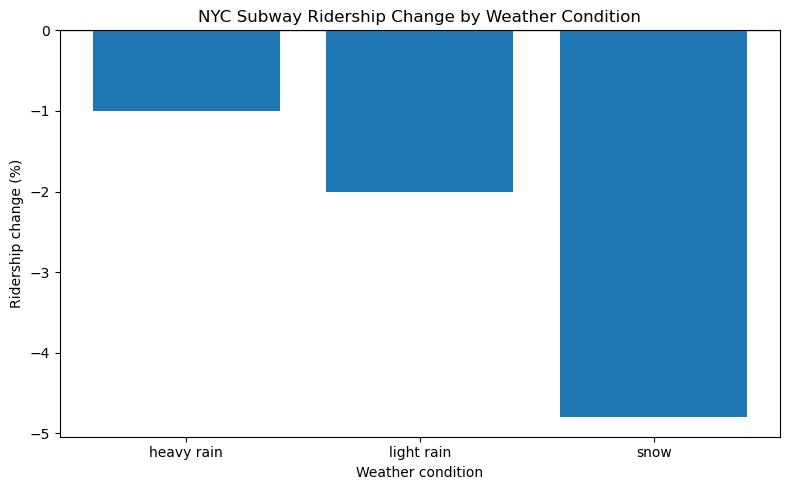

In [44]:
import os
import matplotlib.pyplot as plt

# Create a folder for figures
os.makedirs(RESULTS + "/figures", exist_ok=True)

# Read the saved results
network_plot = (
    spark.read.parquet(GOLD + "/weather_effect")
    .where("condition != 'dry'")
    .orderBy("condition")
    .toPandas()
)

# Create the chart
plt.figure(figsize=(8, 5))
plt.bar(network_plot["condition"], network_plot["change"])
plt.axhline(0, linewidth=1)
plt.ylabel("Ridership change (%)")
plt.xlabel("Weather condition")
plt.title("NYC Subway Ridership Change by Weather Condition")
plt.tight_layout()

# Save and display
plt.savefig(
    RESULTS + "/figures/weather_effect.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

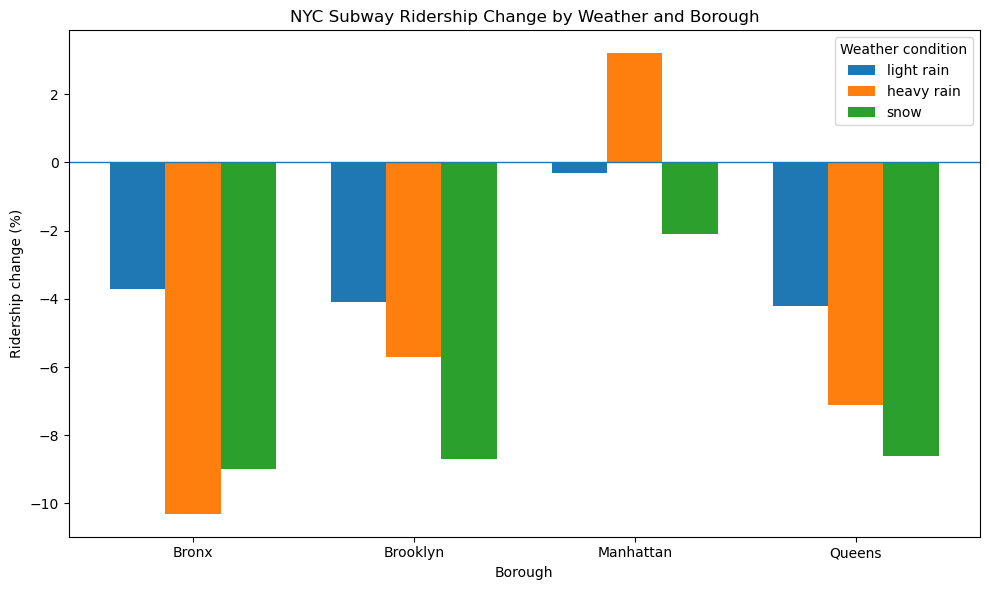

In [53]:
import matplotlib.pyplot as plt

# Read the saved borough-level results
borough_plot = (
    spark.read.parquet(GOLD + "/weather_effect_borough")
    .where("condition != 'dry'")
    .toPandas()
)

# Keep the boroughs and weather conditions in a consistent order
boroughs = ["Bronx", "Brooklyn", "Manhattan", "Queens"]
conditions = ["light rain", "heavy rain", "snow"]

fig, ax = plt.subplots(figsize=(10, 6))

width = 0.25
x = list(range(len(boroughs)))

for i, condition in enumerate(conditions):
    values = [
        borough_plot.loc[
            (borough_plot["borough"] == borough)
            & (borough_plot["condition"] == condition),
            "change"
        ].iloc[0]
        for borough in boroughs
    ]

    positions = [position + (i - 1) * width for position in x]
    ax.bar(positions, values, width=width, label=condition)

ax.axhline(0, linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(boroughs)
ax.set_ylabel("Ridership change (%)")
ax.set_xlabel("Borough")
ax.set_title("NYC Subway Ridership Change by Weather and Borough")
ax.legend(title="Weather condition")
plt.tight_layout()

plt.savefig(
    RESULTS + "/figures/weather_effect_borough.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [54]:
# Show the weather conditions associated with the largest ridership decreases
borough_effect.where(
    "condition != 'dry'"
).orderBy(
    "change"
).select(
    "borough",
    "condition",
    "hours",
    "change"
).show(truncate=False)

+---------+----------+-----+------+
|borough  |condition |hours|change|
+---------+----------+-----+------+
|Bronx    |heavy rain|110  |-10.3 |
|Bronx    |snow      |64   |-9.0  |
|Brooklyn |snow      |64   |-8.7  |
|Queens   |snow      |64   |-8.6  |
|Queens   |heavy rain|110  |-7.1  |
|Brooklyn |heavy rain|110  |-5.7  |
|Queens   |light rain|454  |-4.2  |
|Brooklyn |light rain|454  |-4.1  |
|Bronx    |light rain|454  |-3.7  |
|Manhattan|snow      |64   |-2.1  |
|Manhattan|light rain|454  |-0.3  |
|Manhattan|heavy rain|110  |3.2   |
+---------+----------+-----+------+

